# LoRA Training Results — Trend Analysis

Compares pre/post and mid-training evaluation metrics across LoRA fine-tuning runs.
Metrics come from `pre_post_train_eval_metrics.json` in each output directory.

**Checkpoints per run:** before training (epoch 0), every 5 epochs (when logged), and after training (final epoch).

**Metrics:** WER, aggregate disfluency-token F1/P/R, and per-token F1 on train and test splits.

In [1]:
from __future__ import annotations

import json
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import yaml

plt.style.use("seaborn-v0_8-whitegrid")
pd.set_option("display.max_columns", 20)
pd.set_option("display.float_format", lambda x: f"{x:.4f}")

In [2]:
OUTPUTS_ROOT = Path("/scratch/sathvik/outputs")

RUNS: list[dict] = [
    {
        "run_id": "lora_v2",
        "dir_name": "lora_v2_epochs=10",
        "label": "v2 baseline (weight=2)",
    },
    {
        "run_id": "disfluency_weights",
        "dir_name": "lora_epochs=10_disfluencytoken_weights",
        "label": "disfluency weight=3",
    },
    {
        "run_id": "noiseaug_v1",
        "dir_name": "lora_epochs=10_disfluencytoken_weights_noiseaug",
        "label": "noise aug (white, p=0.7)",
    },
    {
        "run_id": "noiseaug_v2",
        "dir_name": "lora_epochs=10_disfluencytoken_weights_noiseaug_v2",
        "label": "multi aug (p=0.3, r=8)",
    },
    {
        "run_id": "noiseaug_v3",
        "dir_name": "lora_epochs=10_disfluencytoken_weights_noiseaug_v3",
        "label": "multi aug (15 epochs)",
    },
]

DISFLUENCY_TOKEN_ORDER = [
    "[uh]",
    "[um]",
    "[short-pause]",
    "[medium-pause]",
    "[long-pause]",
    "[unclear-speech]",
    "[laughter]",
    "[non-verbal]",
]


def run_dir(spec: dict) -> Path:
    return OUTPUTS_ROOT / spec["dir_name"]


def load_yaml(path: Path) -> dict:
    with path.open() as f:
        return yaml.safe_load(f)


def load_metrics(path: Path) -> dict:
    with path.open() as f:
        return json.load(f)


def extract_run_params(cfg: dict) -> dict:
    data = cfg.get("data") or {}
    lora = cfg.get("lora") or {}
    aug_types = data.get("augmentation_types")
    if aug_types:
        aug_summary = ", ".join(aug_types)
    elif data.get("noise_augmentation_prob") is not None:
        aug_summary = "white_noise only"
    else:
        aug_summary = "none"
    return {
        "num_train_epochs": cfg.get("num_train_epochs"),
        "disfluency_loss_weight": cfg.get("disfluency_loss_weight"),
        "lora_r": lora.get("r"),
        "lora_alpha": lora.get("alpha"),
        "lora_dropout": lora.get("dropout"),
        "learning_rate": cfg.get("learning_rate"),
        "noise_augmentation_prob": data.get("noise_augmentation_prob"),
        "noise_snr_db_min": data.get("noise_snr_db_min"),
        "noise_snr_db_max": data.get("noise_snr_db_max"),
        "augmentation_types": aug_summary,
    }

## Run configuration (varying hyperparameters)

In [3]:
config_rows = []
for spec in RUNS:
    cfg_path = run_dir(spec) / "train_config.yaml"
    if not cfg_path.exists():
        raise FileNotFoundError(cfg_path)
    row = {"run_id": spec["run_id"], "label": spec["label"], "output_dir": spec["dir_name"]}
    row.update(extract_run_params(load_yaml(cfg_path)))
    config_rows.append(row)

config_df = pd.DataFrame(config_rows).set_index("run_id")
display(config_df)

,label,output_dir,num_train_epochs,disfluency_loss_weight,lora_r,lora_alpha,lora_dropout,learning_rate,noise_augmentation_prob,noise_snr_db_min,noise_snr_db_max,augmentation_types
run_id,,,,,,,,,,,,
lora_v2,v2 baseline (weight=2),lora_v2_epochs=10,10,2.0000,16,32,0.0500,0.0001,NaN,NaN,NaN,none
disfluency_weights,disfluency weight=3,lora_epochs=10_disfluencytoken_weights,10,3.0000,16,32,0.0500,0.0001,NaN,NaN,NaN,none
noiseaug_v1,"noise aug (white, p=0.7)",lora_epochs=10_disfluencytoken_weights_noiseaug,10,3.0000,16,32,0.0500,0.0001,0.7000,12.0000,30.0000,white_noise only
noiseaug_v2,"multi aug (p=0.3, r=8)",lora_epochs=10_disfluencytoken_weights_noiseau...,10,3.0000,8,16,0.1000,0.0001,0.3000,12.0000,30.0000,"white_noise, babble, reverb, speed, codec"
noiseaug_v3,multi aug (15 epochs),lora_epochs=10_disfluencytoken_weights_noiseau...,15,3.0000,8,16,0.1000,0.0001,0.3000,12.0000,30.0000,"white_noise, babble, reverb, speed, codec"


## Parse evaluation checkpoints

Stages: `before_train` → `epoch_00N` (every 5 epochs) → `after_train` (final epoch).

In [4]:
def _epoch_from_stage(stage: str, final_epoch: float) -> float:
    if stage == "before_train":
        return 0.0
    if stage == "after_train":
        return float(final_epoch)
    if stage.startswith("epoch_"):
        return float(stage.split("_", 1)[1])
    raise ValueError(stage)


def iter_eval_stages(metrics: dict, final_epoch: float) -> list[tuple[str, float, dict]]:
    stages: list[tuple[str, float, dict]] = [
        ("before_train", 0.0, metrics["before_train"]),
    ]
    for key in sorted(metrics.get("epoch_metrics", {})):
        epoch_num = float(key.split("_", 1)[1])
        stages.append((key, epoch_num, metrics["epoch_metrics"][key]["metrics"]))
    stages.append(("after_train", float(final_epoch), metrics["after_train"]))
    return stages


def flatten_split_metrics(
    run_id: str,
    label: str,
    params: dict,
    stage: str,
    epoch: float,
    split: str,
    block: dict,
) -> list[dict]:
    dtm = block["disfluency_token_metrics"]
    row = {
        "run_id": run_id,
        "label": label,
        "stage": stage,
        "epoch": epoch,
        "split": split,
        "num_samples": block["num_samples"],
        "wer": block["wer"],
        "disfluency_f1": dtm["disfluency_token_f1"],
        "disfluency_precision": dtm["disfluency_token_precision"],
        "disfluency_recall": dtm["disfluency_token_recall"],
        "disfluency_exact_set_acc": dtm["disfluency_token_exact_set_accuracy"],
        "disfluency_order_f1": dtm["disfluency_token_order_f1"],
        "num_train_epochs": params["num_train_epochs"],
        "disfluency_loss_weight": params["disfluency_loss_weight"],
        "lora_r": params["lora_r"],
        "noise_augmentation_prob": params["noise_augmentation_prob"],
        "augmentation_types": params["augmentation_types"],
    }
    rows = [row]
    for token in DISFLUENCY_TOKEN_ORDER:
        stats = dtm["per_token_stats"].get(token, {})
        rows.append(
            {
                **row,
                "token": token,
                "token_f1": stats.get("f1", np.nan),
                "token_precision": stats.get("precision", np.nan),
                "token_recall": stats.get("recall", np.nan),
                "token_tp": stats.get("tp", 0),
                "token_ref_total": stats.get("ref_total", 0),
            }
        )
    return rows


summary_rows: list[dict] = []
per_token_rows: list[dict] = []

for spec in RUNS:
    metrics_path = run_dir(spec) / "pre_post_train_eval_metrics.json"
    cfg = load_yaml(run_dir(spec) / "train_config.yaml")
    params = extract_run_params(cfg)
    metrics = load_metrics(metrics_path)
    final_epoch = float(params["num_train_epochs"])

    for stage, epoch, stage_metrics in iter_eval_stages(metrics, final_epoch):
        for split in ("train", "test"):
            block = stage_metrics[split]
            flat = flatten_split_metrics(
                spec["run_id"], spec["label"], params, stage, epoch, split, block
            )
            summary_rows.append({k: v for k, v in flat[0].items() if k != "token"})
            per_token_rows.extend(flat[1:])

summary_df = pd.DataFrame(summary_rows)
per_token_df = pd.DataFrame(per_token_rows)
print(f"Loaded {len(RUNS)} runs, {len(summary_df)} summary rows, {len(per_token_df)} per-token rows")

Loaded 5 runs, 32 summary rows, 256 per-token rows


## Summary tables — WER and aggregate disfluency F1

In [5]:
display_cols = [
    "label",
    "epoch",
    "stage",
    "split",
    "wer",
    "disfluency_f1",
    "disfluency_precision",
    "disfluency_recall",
    "disfluency_order_f1",
]

for run_id in summary_df["run_id"].unique():
    print(f"\n=== {run_id} ===")
    sub = summary_df[summary_df["run_id"] == run_id].sort_values(["split", "epoch"])
    display(sub[display_cols])


=== lora_v2 ===


,label,epoch,stage,split,wer,disfluency_f1,disfluency_precision,disfluency_recall,disfluency_order_f1
1,v2 baseline (weight=2),0.0000,before_train,test,0.5688,0.0000,0.0000,0.0000,0.0000
3,v2 baseline (weight=2),5.0000,epoch_005,test,0.3450,0.4855,0.5700,0.4228,0.3936
5,v2 baseline (weight=2),10.0000,after_train,test,0.3692,0.5097,0.5287,0.4921,0.3754
0,v2 baseline (weight=2),0.0000,before_train,train,0.4932,0.0000,0.0000,0.0000,0.0000
2,v2 baseline (weight=2),5.0000,epoch_005,train,0.1302,0.7002,0.7439,0.6613,0.6803
4,v2 baseline (weight=2),10.0000,after_train,train,0.0048,0.9895,0.9923,0.9867,0.9876



=== disfluency_weights ===


,label,epoch,stage,split,wer,disfluency_f1,disfluency_precision,disfluency_recall,disfluency_order_f1
7,disfluency weight=3,0.0000,before_train,test,0.5688,0.0000,0.0000,0.0000,0.0000
9,disfluency weight=3,5.0000,epoch_005,test,0.3512,0.4911,0.5601,0.4372,0.3672
11,disfluency weight=3,10.0000,after_train,test,0.3317,0.5470,0.6372,0.4791,0.4220
6,disfluency weight=3,0.0000,before_train,train,0.4932,0.0000,0.0000,0.0000,0.0000
8,disfluency weight=3,5.0000,epoch_005,train,0.1336,0.7107,0.7792,0.6533,0.6901
10,disfluency weight=3,10.0000,after_train,train,0.0040,0.9915,0.9985,0.9847,0.9913



=== noiseaug_v1 ===


,label,epoch,stage,split,wer,disfluency_f1,disfluency_precision,disfluency_recall,disfluency_order_f1
13,"noise aug (white, p=0.7)",0.0000,before_train,test,0.5688,0.0000,0.0000,0.0000,0.0000
15,"noise aug (white, p=0.7)",5.0000,epoch_005,test,0.3648,0.4096,0.4596,0.3694,0.3207
17,"noise aug (white, p=0.7)",10.0000,after_train,test,0.3576,0.5522,0.6221,0.4964,0.3838
12,"noise aug (white, p=0.7)",0.0000,before_train,train,0.4932,0.0000,0.0000,0.0000,0.0000
14,"noise aug (white, p=0.7)",5.0000,epoch_005,train,0.1920,0.6826,0.9071,0.5472,0.6518
16,"noise aug (white, p=0.7)",10.0000,after_train,train,0.0224,0.9666,0.9856,0.9484,0.9609



=== noiseaug_v2 ===


,label,epoch,stage,split,wer,disfluency_f1,disfluency_precision,disfluency_recall,disfluency_order_f1
19,"multi aug (p=0.3, r=8)",0.0000,before_train,test,0.5688,0.0000,0.0000,0.0000,0.0000
21,"multi aug (p=0.3, r=8)",5.0000,epoch_005,test,0.3816,0.4254,0.5878,0.3333,0.3291
23,"multi aug (p=0.3, r=8)",10.0000,after_train,test,0.3760,0.4718,0.4792,0.4646,0.3357
18,"multi aug (p=0.3, r=8)",0.0000,before_train,train,0.4932,0.0000,0.0000,0.0000,0.0000
20,"multi aug (p=0.3, r=8)",5.0000,epoch_005,train,0.2330,0.5656,0.6984,0.4752,0.5233
22,"multi aug (p=0.3, r=8)",10.0000,after_train,train,0.0558,0.9271,0.9784,0.8809,0.9163



=== noiseaug_v3 ===


,label,epoch,stage,split,wer,disfluency_f1,disfluency_precision,disfluency_recall,disfluency_order_f1
25,multi aug (15 epochs),0.0000,before_train,test,0.5688,0.0000,0.0000,0.0000,0.0000
27,multi aug (15 epochs),5.0000,epoch_005,test,0.4104,0.4405,0.5802,0.3550,0.3542
29,multi aug (15 epochs),10.0000,epoch_010,test,0.3990,0.5399,0.5475,0.5325,0.3703
31,multi aug (15 epochs),15.0000,after_train,test,0.3640,0.5168,0.5651,0.4762,0.3696
24,multi aug (15 epochs),0.0000,before_train,train,0.4932,0.0000,0.0000,0.0000,0.0000
26,multi aug (15 epochs),5.0000,epoch_005,train,0.2305,0.5760,0.7283,0.4764,0.5497
28,multi aug (15 epochs),10.0000,epoch_010,train,0.0172,0.9647,0.9581,0.9714,0.9597
30,multi aug (15 epochs),15.0000,after_train,train,0.0015,0.9960,0.9988,0.9932,0.9958


## Per-token F1 (test split) at each checkpoint

In [6]:
for run_id in per_token_df["run_id"].unique():
    print(f"\n=== {run_id} — test per-token F1 ===")
    sub = per_token_df[(per_token_df["run_id"] == run_id) & (per_token_df["split"] == "test")]
    pivot = sub.pivot_table(index="token", columns="epoch", values="token_f1", aggfunc="first")
    pivot = pivot.reindex(DISFLUENCY_TOKEN_ORDER)
    pivot.columns = [f"epoch {int(c)}" if c == int(c) else f"epoch {c}" for c in pivot.columns]
    display(pivot)


=== lora_v2 — test per-token F1 ===


,epoch 0,epoch 5,epoch 10
token,,,
[uh],0.0000,0.7509,0.7575
[um],0.0000,0.7436,0.7500
[short-pause],0.0000,0.2590,0.4172
[medium-pause],0.0000,0.3125,0.2632
[long-pause],0.0000,0.5062,0.5570
[unclear-speech],0.0000,0.2491,0.3161
[laughter],0.0000,0.4407,0.2917
[non-verbal],0.0000,0.2703,0.4211



=== disfluency_weights — test per-token F1 ===


,epoch 0,epoch 5,epoch 10
token,,,
[uh],0.0000,0.7458,0.7559
[um],0.0000,0.5825,0.7607
[short-pause],0.0000,0.2371,0.3952
[medium-pause],0.0000,0.3077,0.2821
[long-pause],0.0000,0.5161,0.5610
[unclear-speech],0.0000,0.3721,0.4000
[laughter],0.0000,0.4000,0.3704
[non-verbal],0.0000,0.3889,0.3590



=== noiseaug_v1 — test per-token F1 ===


,epoch 0,epoch 5,epoch 10
token,,,
[uh],0.0000,0.7536,0.7344
[um],0.0000,0.7582,0.7702
[short-pause],0.0000,0.2481,0.4385
[medium-pause],0.0000,0.2432,0.2785
[long-pause],0.0000,0.4218,0.4586
[unclear-speech],0.0000,0.1523,0.4861
[laughter],0.0000,0.2222,0.4407
[non-verbal],0.0000,0.1875,0.3404



=== noiseaug_v2 — test per-token F1 ===


,epoch 0,epoch 5,epoch 10
token,,,
[uh],0.0000,0.5149,0.7099
[um],0.0000,0.7500,0.7500
[short-pause],0.0000,0.1983,0.4044
[medium-pause],0.0000,0.1905,0.2500
[long-pause],0.0000,0.3651,0.5150
[unclear-speech],0.0000,0.2955,0.2602
[laughter],0.0000,0.2979,0.3774
[non-verbal],0.0000,0.3125,0.3784



=== noiseaug_v3 — test per-token F1 ===


,epoch 0,epoch 5,epoch 10,epoch 15
token,,,,
[uh],0.0000,0.7517,0.7593,0.7448
[um],0.0000,0.7391,0.7821,0.7484
[short-pause],0.0000,0.1053,0.4859,0.4561
[medium-pause],0.0000,0.2353,0.4176,0.3467
[long-pause],0.0000,0.4173,0.5202,0.4459
[unclear-speech],0.0000,0.1935,0.3641,0.3432
[laughter],0.0000,0.3846,0.3860,0.3704
[non-verbal],0.0000,0.3243,0.4615,0.4783


## Trend plots — WER and aggregate F1 vs epoch

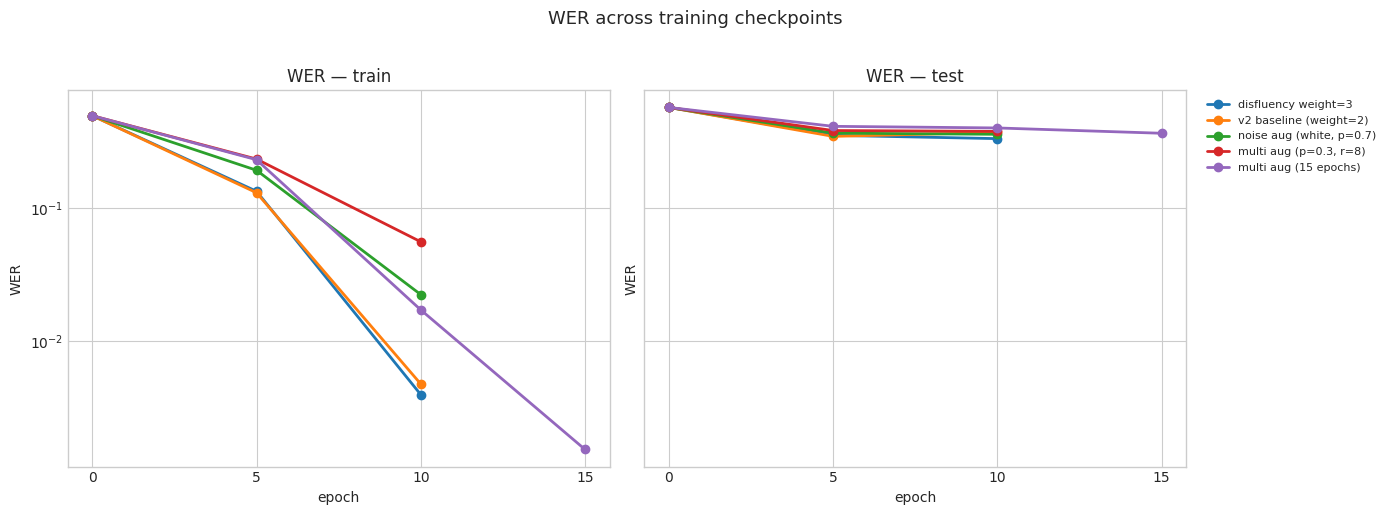

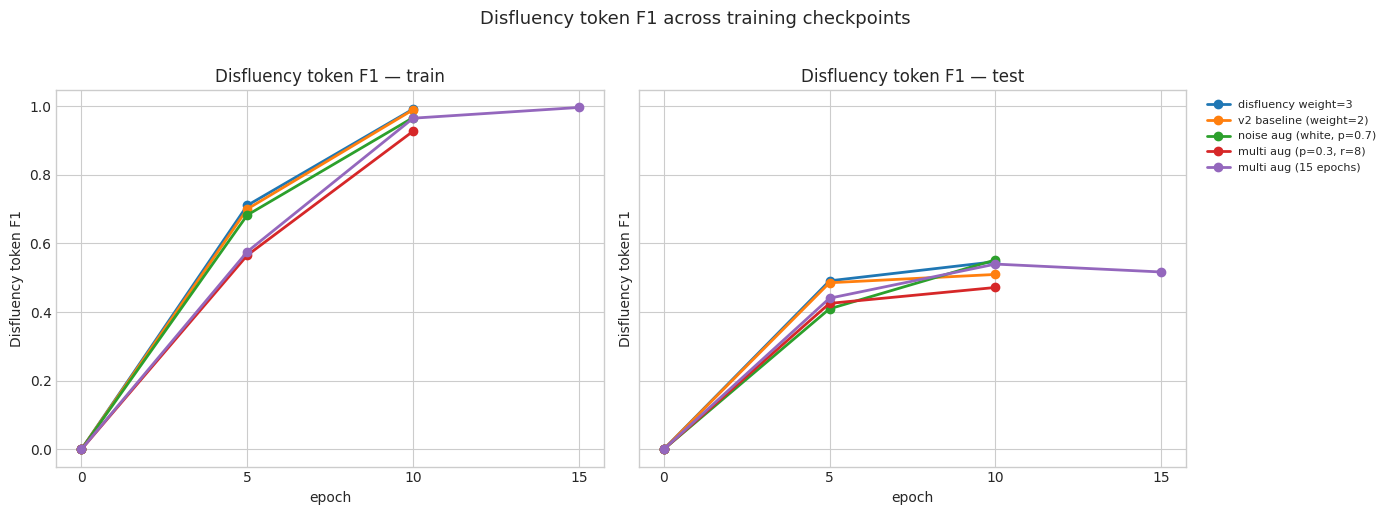

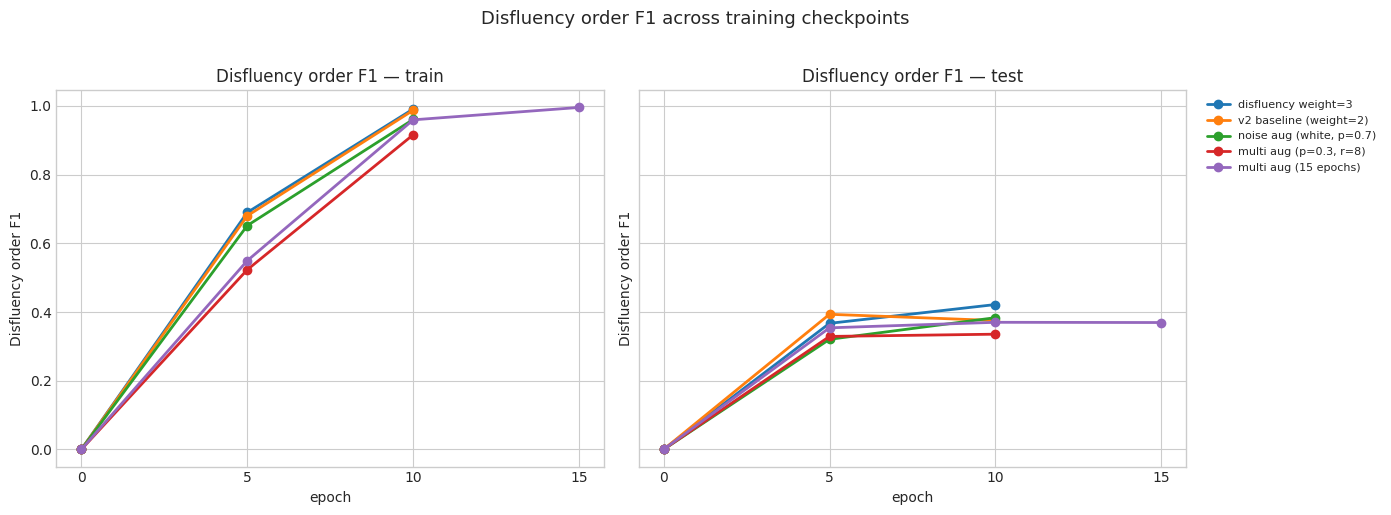

In [7]:
def plot_metric_trends(metric_col: str, ylabel: str, *, log_y: bool = False) -> None:
    fig, axes = plt.subplots(1, 2, figsize=(14, 5), sharey=True)
    for ax, split in zip(axes, ["train", "test"]):
        sub = summary_df[summary_df["split"] == split]
        for run_id, grp in sub.groupby("run_id"):
            grp = grp.sort_values("epoch")
            ax.plot(
                grp["epoch"],
                grp[metric_col],
                marker="o",
                linewidth=2,
                label=grp["label"].iloc[0],
            )
        ax.set_title(f"{ylabel} — {split}")
        ax.set_xlabel("epoch")
        ax.set_ylabel(ylabel)
        ax.set_xticks(sorted(sub["epoch"].unique()))
        if log_y:
            ax.set_yscale("log")
    axes[1].legend(bbox_to_anchor=(1.02, 1), loc="upper left", fontsize=8)
    fig.suptitle(f"{ylabel} across training checkpoints", fontsize=13, y=1.02)
    plt.tight_layout()
    plt.show()


plot_metric_trends("wer", "WER", log_y=True)
plot_metric_trends("disfluency_f1", "Disfluency token F1")
plot_metric_trends("disfluency_order_f1", "Disfluency order F1")

## Per-token F1 trends (test split, one subplot per run)

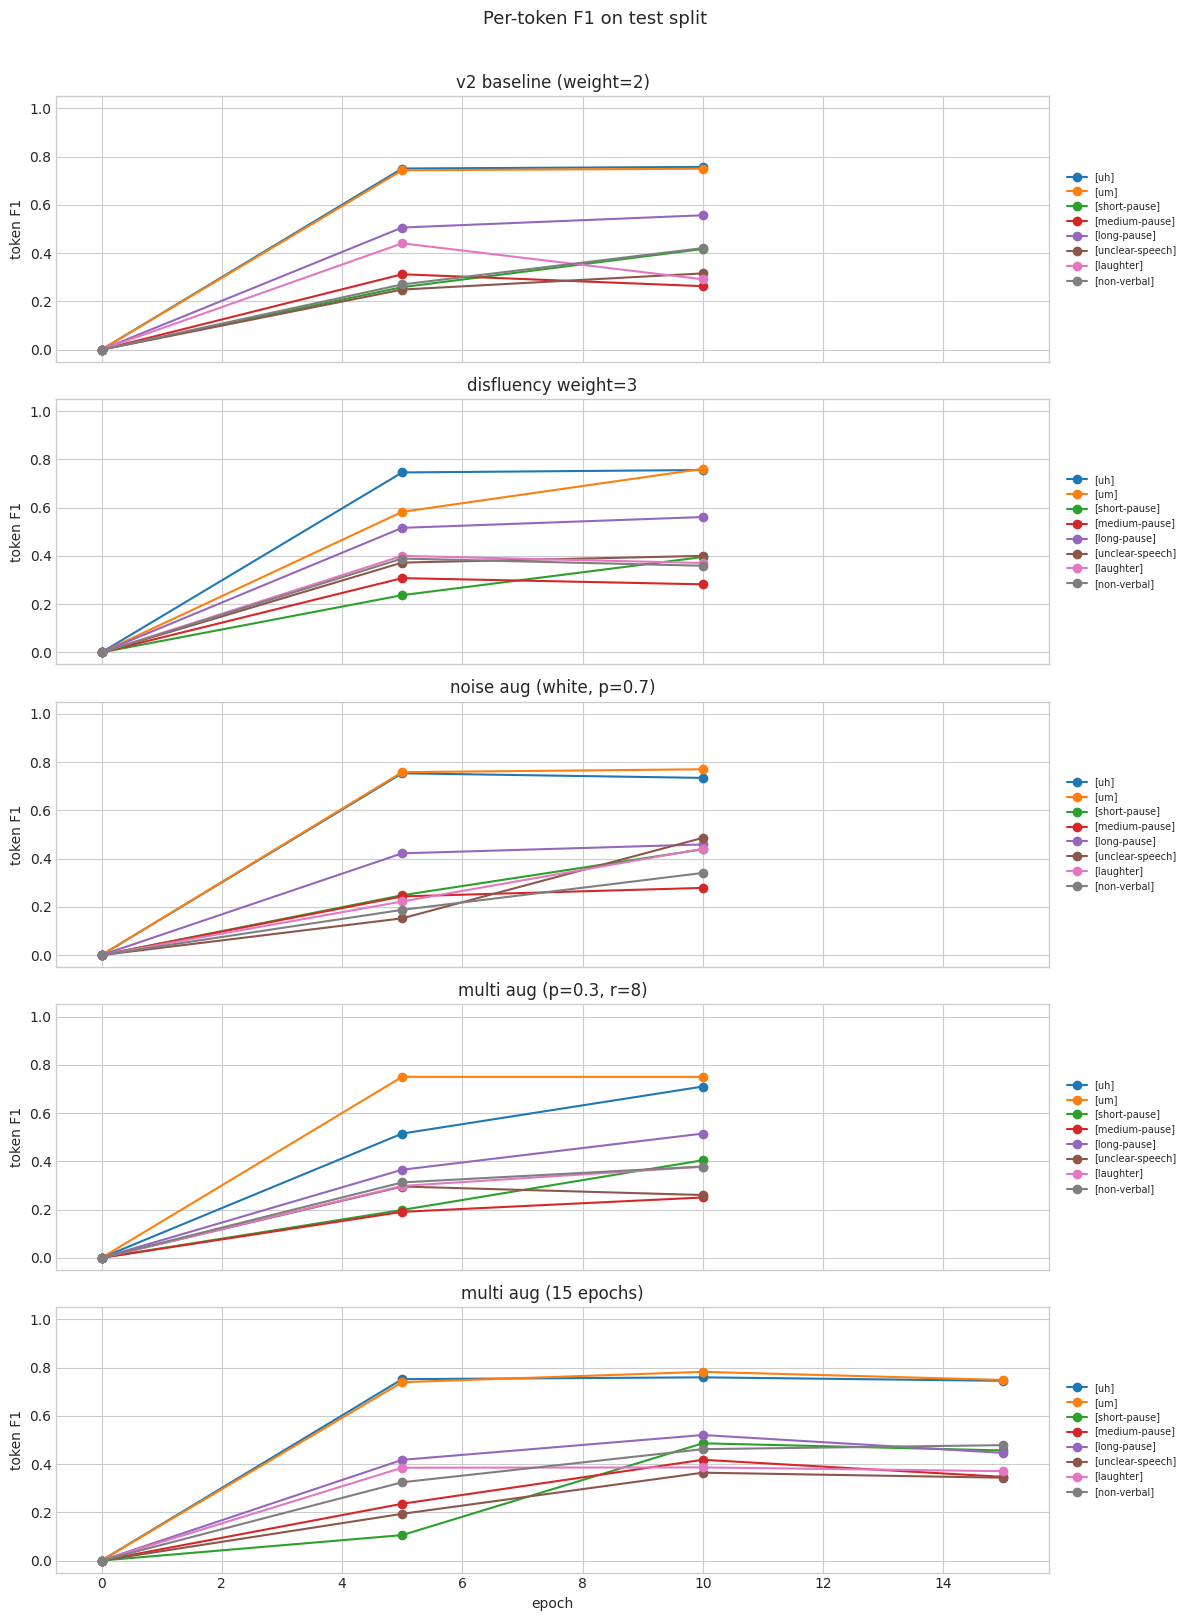

In [8]:
n_runs = len(RUNS)
fig, axes = plt.subplots(n_runs, 1, figsize=(12, 3.2 * n_runs), sharex=True)
if n_runs == 1:
    axes = [axes]

for ax, spec in zip(axes, RUNS):
    sub = per_token_df[
        (per_token_df["run_id"] == spec["run_id"]) & (per_token_df["split"] == "test")
    ]
    for token in DISFLUENCY_TOKEN_ORDER:
        tok = sub[sub["token"] == token].sort_values("epoch")
        ax.plot(tok["epoch"], tok["token_f1"], marker="o", linewidth=1.5, label=token)
    ax.set_title(spec["label"])
    ax.set_ylabel("token F1")
    ax.set_ylim(-0.05, 1.05)
    ax.legend(loc="center left", bbox_to_anchor=(1.01, 0.5), fontsize=7)

axes[-1].set_xlabel("epoch")
fig.suptitle("Per-token F1 on test split", fontsize=13, y=1.01)
plt.tight_layout()
plt.show()

## Cross-run comparison at final epoch (after training)

,disfluency_f1 (test),disfluency_f1 (train),disfluency_precision (test),disfluency_precision (train),disfluency_recall (test),disfluency_recall (train),wer (test),wer (train)
run_label,,,,,,,,
disfluency weight=3,0.5470,0.9915,0.6372,0.9985,0.4791,0.9847,0.3317,0.0040
multi aug (15 epochs),0.5168,0.9960,0.5651,0.9988,0.4762,0.9932,0.3640,0.0015
"multi aug (p=0.3, r=8)",0.4718,0.9271,0.4792,0.9784,0.4646,0.8809,0.3760,0.0558
"noise aug (white, p=0.7)",0.5522,0.9666,0.6221,0.9856,0.4964,0.9484,0.3576,0.0224
v2 baseline (weight=2),0.5097,0.9895,0.5287,0.9923,0.4921,0.9867,0.3692,0.0048


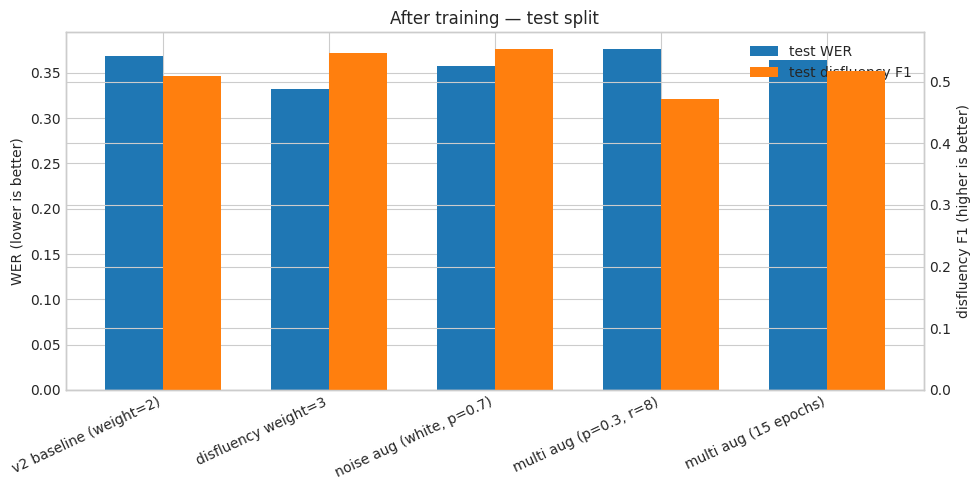

In [9]:
final = summary_df[summary_df["stage"] == "after_train"].copy()
final["run_label"] = final["label"]

compare = final.pivot_table(
    index="run_label",
    columns="split",
    values=["wer", "disfluency_f1", "disfluency_recall", "disfluency_precision"],
)
compare.columns = [f"{metric} ({split})" for metric, split in compare.columns]
display(compare.sort_index())

fig, ax = plt.subplots(figsize=(10, 5))
x = np.arange(len(final["run_id"].unique()))
runs_order = list(final["run_id"].unique())
labels = [final.loc[final["run_id"] == r, "label"].iloc[0] for r in runs_order]
test_wer = [final.loc[(final["run_id"] == r) & (final["split"] == "test"), "wer"].iloc[0] for r in runs_order]
test_f1 = [final.loc[(final["run_id"] == r) & (final["split"] == "test"), "disfluency_f1"].iloc[0] for r in runs_order]

width = 0.35
ax.bar(x - width / 2, test_wer, width, label="test WER")
ax2 = ax.twinx()
ax2.bar(x + width / 2, test_f1, width, color="tab:orange", label="test disfluency F1")
ax.set_xticks(x)
ax.set_xticklabels(labels, rotation=25, ha="right")
ax.set_ylabel("WER (lower is better)")
ax2.set_ylabel("disfluency F1 (higher is better)")
ax.set_title("After training — test split")
lines1, labels1 = ax.get_legend_handles_labels()
lines2, labels2 = ax2.get_legend_handles_labels()
ax.legend(lines1 + lines2, labels1 + labels2, loc="upper right")
plt.tight_layout()
plt.show()

## Training loss curves (from `loss_curves.json`)

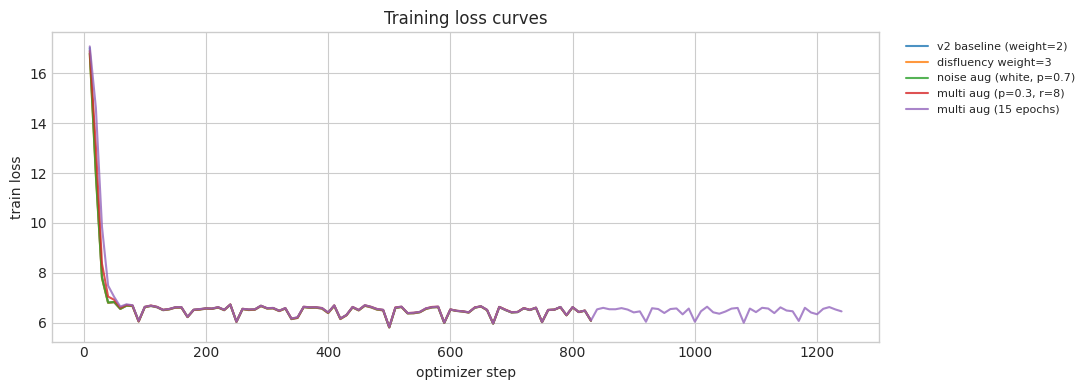

In [10]:
fig, ax = plt.subplots(figsize=(11, 4))
for spec in RUNS:
    loss_path = run_dir(spec) / "loss_curves.json"
    if not loss_path.exists():
        continue
    curves = load_metrics(loss_path)
    steps = [p["step"] for p in curves.get("train_loss", [])]
    losses = [p["loss"] for p in curves.get("train_loss", [])]
    if steps:
        ax.plot(steps, losses, alpha=0.8, label=spec["label"])

ax.set_xlabel("optimizer step")
ax.set_ylabel("train loss")
ax.set_title("Training loss curves")
ax.legend(fontsize=8, bbox_to_anchor=(1.02, 1), loc="upper left")
plt.tight_layout()
plt.show()

## Generalization gap (train vs test) at each checkpoint

Positive gap = train metric better than test (expected for F1; for WER, gap = test WER − train WER).

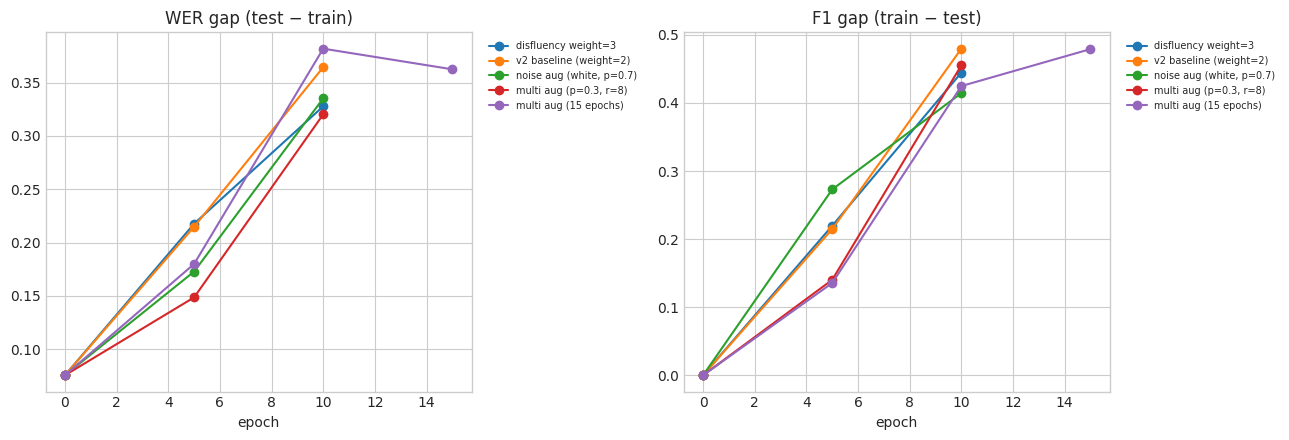

,run_id,label,epoch,wer_gap_test_minus_train,f1_gap_train_minus_test
0,disfluency_weights,disfluency weight=3,0.0000,0.0756,0.0000
1,disfluency_weights,disfluency weight=3,5.0000,0.2176,0.2196
2,disfluency_weights,disfluency weight=3,10.0000,0.3277,0.4446
3,lora_v2,v2 baseline (weight=2),0.0000,0.0756,0.0000
4,lora_v2,v2 baseline (weight=2),5.0000,0.2148,0.2147
5,lora_v2,v2 baseline (weight=2),10.0000,0.3644,0.4798
6,noiseaug_v1,"noise aug (white, p=0.7)",0.0000,0.0756,0.0000
7,noiseaug_v1,"noise aug (white, p=0.7)",5.0000,0.1728,0.2730
8,noiseaug_v1,"noise aug (white, p=0.7)",10.0000,0.3352,0.4145
9,noiseaug_v2,"multi aug (p=0.3, r=8)",0.0000,0.0756,0.0000


In [11]:
gap_rows = []
for (run_id, epoch), grp in summary_df.groupby(["run_id", "epoch"]):
    train = grp[grp["split"] == "train"].iloc[0]
    test = grp[grp["split"] == "test"].iloc[0]
    gap_rows.append(
        {
            "run_id": run_id,
            "label": train["label"],
            "epoch": epoch,
            "wer_gap_test_minus_train": test["wer"] - train["wer"],
            "f1_gap_train_minus_test": train["disfluency_f1"] - test["disfluency_f1"],
        }
    )
gap_df = pd.DataFrame(gap_rows)

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
for ax, col, title in zip(
    axes,
    ["wer_gap_test_minus_train", "f1_gap_train_minus_test"],
    ["WER gap (test − train)", "F1 gap (train − test)"],
):
    for run_id, grp in gap_df.groupby("run_id"):
        grp = grp.sort_values("epoch")
        ax.plot(grp["epoch"], grp[col], marker="o", label=grp["label"].iloc[0])
    ax.set_xlabel("epoch")
    ax.set_title(title)
    ax.legend(fontsize=7, bbox_to_anchor=(1.02, 1), loc="upper left")
plt.tight_layout()
plt.show()

display(gap_df.sort_values(["run_id", "epoch"]))